# 卷积网络图像分类：从手写数字到 CNN

**课程对象：** 刚刚学习卷积神经网络的中职学生  
**建议课时：** 2～3 课时（可根据学生操作速度调整）  
**本节项目：** 使用卷积神经网络（CNN）识别 0～9 的手写数字

---

## 一、学习目标

1. 能够说出图像像素矩阵、卷积核、特征图、池化层和分类层的基本作用；
2. 能够使用 PyTorch 搭建一个包含卷积层、池化层和全连接层的图像分类模型；
3. 能够运行模型训练与测试流程，并根据准确率、损失曲线和混淆矩阵评价分类效果；
4. 能够输入一张手写数字图像，输出模型预测的数字类别。

## 二、任务情境

假设学校正在制作一个“手写数字识别”小工具：学生写下一个数字，程序自动判断它是 0、1、2……还是 9。本节课将完成一个最小可运行版本。

我们使用 `scikit-learn` 自带的手写数字数据集。每张图片只有 **8×8 个像素**，类别为 0～9，一共 10 类。数据集随库安装，不需要另外下载图片，适合在课堂网络不稳定时使用。

## 三、学习路线

1. 查看图片数据，理解“图像就是数字矩阵”；
2. 观察卷积核如何提取局部特征；
3. 准备训练集、验证集和测试集；
4. 搭建 CNN 并训练；
5. 评价模型并尝试预测新样本。

> **运行提示：** 建议按顺序运行每个代码单元。若提示缺少库，可在当前 Python 环境中执行 `pip install torch scikit-learn matplotlib scipy`。

## 1. 导入本节需要的工具

先导入数据处理、绘图和深度学习工具，并固定随机种子，尽量让每次实验结果更稳定。

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt

# 按系统可用字体优先选择中文字体，避免中文图表标题显示为方框
plt.rcParams["font.sans-serif"] = ["Noto Sans CJK SC", "Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from scipy.signal import correlate2d

# 固定随机种子，便于课堂复现实验
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# 优先使用 GPU；如果没有可用 GPU，则使用 CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch 版本：", torch.__version__)
print("当前计算设备：", device)
print("准备就绪！")

PyTorch 版本： 2.10.0+cpu
当前计算设备： cpu
准备就绪！


## 2. 认识图像分类数据集

图像分类的目标是：**输入一张图像，预测它属于哪个类别**。

- 输入：一张手写数字图片；
- 输出：0～9 中的一个数字类别；
- 本任务是多分类任务，因为一共有 10 个类别。

下面读取数据，并查看数据量、图像尺寸和标签。

In [2]:
digits = load_digits()
images = digits.images          # 图像数组，形状为 [样本数, 8, 8]
labels = digits.target          # 标签数组，形状为 [样本数]

print("图像数据形状：", images.shape)
print("标签数据形状：", labels.shape)
print("类别：", np.unique(labels))
print("单张图片的像素范围：", images.min(), "到", images.max())

图像数据形状： (1797, 8, 8)
标签数据形状： (1797,)
类别： [0 1 2 3 4 5 6 7 8 9]
单张图片的像素范围： 0.0 到 16.0


### 2.1 把图片显示出来

观察：不同数字在像素分布上有什么差异？为什么计算机可以尝试从这些差异中学习？

/tmp/ipykernel_694/1573610330.py:7: UserWarning: Glyph 26631 (\N{CJK UNIFIED IDEOGRAPH-6807}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_694/1573610330.py:7: UserWarning: Glyph 31614 (\N{CJK UNIFIED IDEOGRAPH-7B7E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_694/1573610330.py:7: UserWarning: Glyph 65306 (\N{FULLWIDTH COLON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_694/1573610330.py:7: UserWarning: Glyph 25163 (\N{CJK UNIFIED IDEOGRAPH-624B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_694/1573610330.py:7: UserWarning: Glyph 20889 (\N{CJK UNIFIED IDEOGRAPH-5199}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_694/1573610330.py:7: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_694/1573610330.py:7: UserWarning: Glyph 23383 (\N{CJK UNIFIED IDEOGRAPH-5B57}) missing from font(s) De

/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 26631 (\N{CJK UNIFIED IDEOGRAPH-6807}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 31614 (\N{CJK UNIFIED IDEOGRAPH-7B7E}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 65306 (\N{FULLWIDTH COLON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 25163 (\N{CJK UNIFIED IDEOGRAPH-624B}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 20889 (\N{CJK UNIFIED IDEOGRAPH-5199}) missing from font(s) DejaVu Sans.
  fig.canvas.print

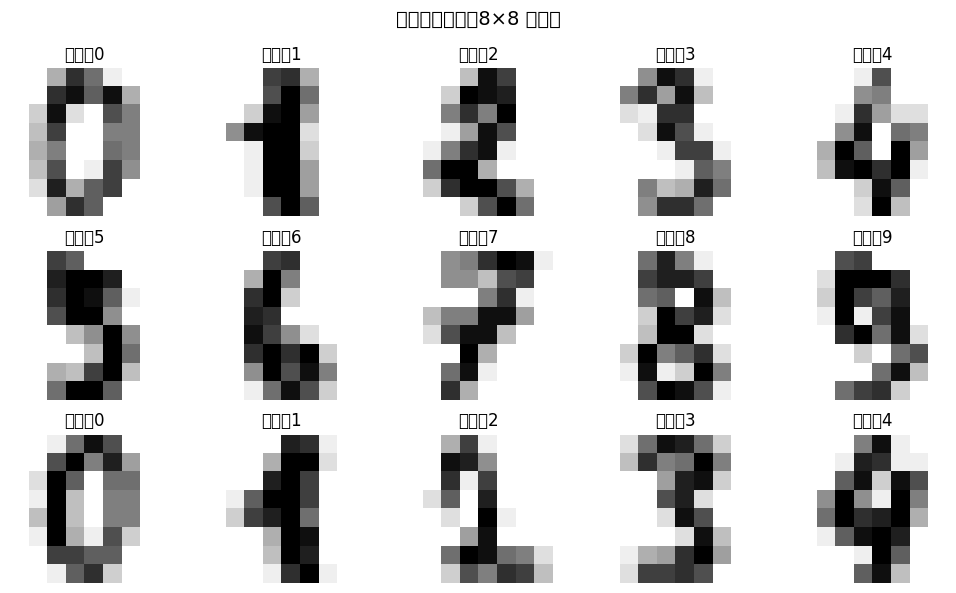

In [3]:
fig, axes = plt.subplots(3, 5, figsize=(10, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i], cmap="gray_r", vmin=0, vmax=16)
    ax.set_title(f"标签：{labels[i]}")
    ax.axis("off")
plt.suptitle("手写数字样本（8×8 像素）", fontsize=14)
plt.tight_layout()
plt.show()

### 2.2 图像为什么可以用数字表示？

灰度图可以看作一个二维数字矩阵：每个数字表示一个像素的亮度。当前数据集的像素值范围是 0～16，数值越大，像素越亮。

请运行代码，查看一张图片对应的矩阵。

/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 30697 (\N{CJK UNIFIED IDEOGRAPH-77E9}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 38453 (\N{CJK UNIFIED IDEOGRAPH-9635}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 21487 (\N{CJK UNIFIED IDEOGRAPH-53EF}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 35270 (\N{CJK UNIFIED IDEOGRAPH-89C6}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 21270 (\N{CJK UNIFIED IDEOGRAPH-5316}) missing from font(s) DejaVu Sans.
  fig.c

该图片对应的数字标签： 0
像素矩阵：
[[ 0  0  5 13  9  1  0  0]
 [ 0  0 13 15 10 15  5  0]
 [ 0  3 15  2  0 11  8  0]
 [ 0  4 12  0  0  8  8  0]
 [ 0  5  8  0  0  9  8  0]
 [ 0  4 11  0  1 12  7  0]
 [ 0  2 14  5 10 12  0  0]
 [ 0  0  6 13 10  0  0  0]]


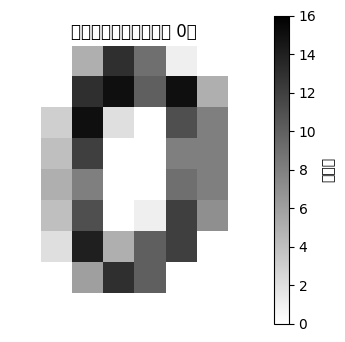

In [4]:
sample_index = 0
sample_image = images[sample_index]

print("该图片对应的数字标签：", labels[sample_index])
print("像素矩阵：")
print(sample_image.astype(int))

plt.figure(figsize=(4, 4))
plt.imshow(sample_image, cmap="gray_r", vmin=0, vmax=16)
plt.colorbar(label="像素值")
plt.title(f"像素矩阵可视化（标签 {labels[sample_index]}）")
plt.axis("off")
plt.show()

## 3. 卷积操作：从局部区域中提取特征

CNN 不会一开始就直接“理解”数字，而是通过卷积层，从图片局部区域提取边缘、线条、笔画等特征，再逐步组合这些特征用于分类。

**卷积核（Kernel）** 是一个小矩阵。它在图像上移动，对局部像素进行计算，产生新的矩阵，称为**特征图（Feature Map）**。

下面先用一个固定的边缘检测卷积核做演示。实际 CNN 中的卷积核通常会在训练过程中自动学习，不需要我们手动指定。

/tmp/ipykernel_694/1171998274.py:24: UserWarning: Glyph 21407 (\N{CJK UNIFIED IDEOGRAPH-539F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_694/1171998274.py:24: UserWarning: Glyph 22987 (\N{CJK UNIFIED IDEOGRAPH-59CB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_694/1171998274.py:24: UserWarning: Glyph 22270 (\N{CJK UNIFIED IDEOGRAPH-56FE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_694/1171998274.py:24: UserWarning: Glyph 20687 (\N{CJK UNIFIED IDEOGRAPH-50CF}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_694/1171998274.py:24: UserWarning: Glyph 21367 (\N{CJK UNIFIED IDEOGRAPH-5377}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_694/1171998274.py:24: UserWarning: Glyph 31215 (\N{CJK UNIFIED IDEOGRAPH-79EF}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_694/1171998274.py:24: UserWarning: Glyph 26680 (\N{CJK UNIFIED IDEOGRAPH-6838}) missi

/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 21407 (\N{CJK UNIFIED IDEOGRAPH-539F}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 22987 (\N{CJK UNIFIED IDEOGRAPH-59CB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 22270 (\N{CJK UNIFIED IDEOGRAPH-56FE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 21367 (\N{CJK UNIFIED IDEOGRAPH-5377}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 31215 (\N{CJK UNIFIED IDEOGRAPH-79EF}) missing from font(s) DejaVu Sans.
  fig.c

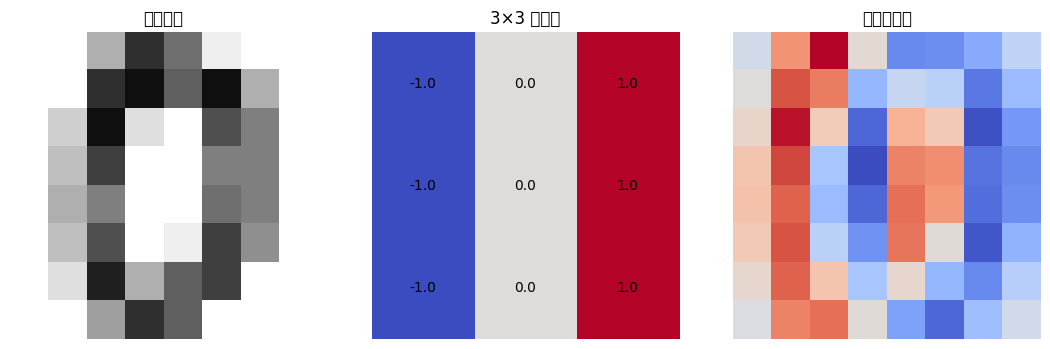

原始图像形状： (8, 8)
卷积核形状： (3, 3)
特征图形状： (8, 8)


In [5]:
# 一个简单的垂直边缘检测核（用于演示）
edge_kernel = np.array([
    [-1, 0, 1],
    [-1, 0, 1],
    [-1, 0, 1]
], dtype=np.float32)

# 对示例图片执行局部卷积计算，得到特征图
feature_map = correlate2d(sample_image, edge_kernel, mode="same", boundary="symm")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
axes[0].imshow(sample_image, cmap="gray_r", vmin=0, vmax=16)
axes[0].set_title("原始图像")
axes[1].imshow(edge_kernel, cmap="coolwarm", vmin=-1, vmax=1)
axes[1].set_title("3×3 卷积核")
axes[1].set_xticks(range(3)); axes[1].set_yticks(range(3))
for r in range(3):
    for c in range(3):
        axes[1].text(c, r, str(edge_kernel[r, c]), ha="center", va="center")
axes[2].imshow(feature_map, cmap="coolwarm")
axes[2].set_title("输出特征图")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

print("原始图像形状：", sample_image.shape)
print("卷积核形状：", edge_kernel.shape)
print("特征图形状：", feature_map.shape)

### 3.1 CNN 常见组件

| 组件 | 入门理解 | 在本节中的作用 |
|---|---|---|
| 卷积层 `Conv2d` | 用多个可学习的小矩阵扫描图像 | 提取局部特征 |
| 激活函数 `ReLU` | 将负数变为 0，增加网络的非线性表达能力 | 让模型能学习更复杂的规律 |
| 池化层 `MaxPool2d` | 在小区域内保留较大的响应值 | 缩小特征图，减少后续计算 |
| 展平 `Flatten` | 把多维特征排成一列 | 连接卷积部分与分类部分 |
| 全连接层 `Linear` | 综合已有特征进行判断 | 输出 10 个类别的分数 |

**提醒：** 卷积层里的卷积核数量是可以设置的。模型训练会调整卷积核中的参数，使它们逐渐学到有助于分类的特征。

## 4. 数据预处理与数据集划分

神经网络需要先把数据整理成适合模型输入的格式。

1. **归一化：** 将像素值从 0～16 缩放到 0～1；
2. **划分数据：** 训练集用来更新模型参数，验证集用来观察训练过程中的表现，测试集用于训练完成后的最终评价；
3. **调整形状：** PyTorch 的二维卷积输入格式为 `[批次大小, 通道数, 图片高度, 图片宽度]`，灰度图的通道数为 1。

本次按照约 70% / 15% / 15% 的比例划分数据。

In [6]:
# 归一化：原始像素 0～16 -> 浮点数 0～1
X = images.astype(np.float32) / 16.0
y = labels.astype(np.int64)

# 第一步：先留出 15% 作为测试集
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, random_state=SEED, stratify=y
)

# 第二步：从剩余数据中划分出约 15% 的验证集
val_ratio_in_temp = 0.15 / 0.85
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=val_ratio_in_temp,
    random_state=SEED, stratify=y_temp
)

print(f"训练集：{len(X_train)} 张")
print(f"验证集：{len(X_val)} 张")
print(f"测试集：{len(X_test)} 张")
print("归一化后像素范围：", X.min(), "到", X.max())

训练集：1257 张
验证集：270 张
测试集：270 张
归一化后像素范围： 0.0 到 1.0


### 4.1 转成 PyTorch 张量

`Tensor` 是 PyTorch 中用于保存和计算数据的主要数据结构。我们还要给图片增加一个通道维度：例如单张灰度图从 `8×8` 变成 `1×8×8`。

In [7]:
def make_tensor_dataset(X_part, y_part):
    # [样本数, 8, 8] -> [样本数, 1, 8, 8]
    x_tensor = torch.tensor(X_part, dtype=torch.float32).unsqueeze(1)
    y_tensor = torch.tensor(y_part, dtype=torch.long)
    return TensorDataset(x_tensor, y_tensor)

train_dataset = make_tensor_dataset(X_train, y_train)
val_dataset = make_tensor_dataset(X_val, y_val)
test_dataset = make_tensor_dataset(X_test, y_test)

BATCH_SIZE = 64
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

# 看看一个批次的数据形状
first_images, first_labels = next(iter(train_loader))
print("一个批次的图像形状：", first_images.shape)
print("一个批次的标签形状：", first_labels.shape)
print("图像张量的数据类型：", first_images.dtype)
print("标签张量的数据类型：", first_labels.dtype)

一个批次的图像形状： torch.Size([64, 1, 8, 8])
一个批次的标签形状： torch.Size([64])
图像张量的数据类型： torch.float32
标签张量的数据类型： torch.int64


## 5. 搭建卷积神经网络

我们使用一个小型 CNN，适合在课堂上理解模型的基本结构：

`输入图像 → 卷积 → ReLU → 池化 → 卷积 → ReLU → 池化 → 展平 → 全连接层 → 10 类分数`

为了跟踪图像尺寸：

- 输入：`1×8×8`；
- 第一次池化后：`16×4×4`；
- 第二次池化后：`32×2×2`；
- 展平后：`32×2×2 = 128` 个数；
- 最后一层输出 10 个分数，分别对应数字 0～9。

这些输出分数通常称为 **logits**。训练时将 logits 和真实标签交给交叉熵损失函数；预测时可以再使用 Softmax 将分数转换为概率。

In [8]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 2 * 2, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

model = SimpleCNN().to(device)
print(model)

# 计算模型中需要学习的参数数量
total_params = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
print(f"可训练参数总数：{total_params:,}")

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=128, out_features=10, bias=True)
  )
)
可训练参数总数：6,090


### 5.1 检查数据经过模型后的形状

在实际训练前，先用一个批次的数据进行“试运行”。这一步可以帮助我们提前发现输入维度和网络结构不匹配的问题。

In [9]:
model.eval()
with torch.no_grad():
    sample_batch = first_images[:4].to(device)
    sample_output = model(sample_batch)

print("输入形状：", sample_batch.shape)
print("输出形状：", sample_output.shape)
print("说明：4 张图片，每张图片输出 10 个类别分数。")

输入形状： torch.Size([4, 1, 8, 8])
输出形状： torch.Size([4, 10])
说明：4 张图片，每张图片输出 10 个类别分数。


## 6. 配置训练过程

训练时，模型先做出预测，再把预测与真实标签进行比较，根据误差调整参数。

- **损失函数 `CrossEntropyLoss`：** 衡量分类预测与真实标签之间的差距；
- **优化器 `Adam`：** 根据梯度更新模型参数；
- **学习率 `0.001`：** 控制每次参数更新的步幅；
- **Epoch：** 模型完整遍历一次训练集称为 1 个 Epoch；
- **Batch：** 每次送入模型的一小批样本。

本节先训练 20 个 Epoch。训练时间会受到计算机性能影响。

In [10]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
EPOCHS = 20

train_losses = []
val_accuracies = []

def evaluate_accuracy(data_loader, model):
    model.eval()
    total = 0
    correct = 0
    with torch.no_grad():
        for batch_x, batch_y in data_loader:
            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device)
            logits = model(batch_x)
            predictions = logits.argmax(dim=1)
            total += batch_y.size(0)
            correct += (predictions == batch_y).sum().item()
    return correct / total

print("训练配置完成。")

训练配置完成。


## 7. 开始训练 CNN

重点观察两个问题：

1. 每个 Epoch 结束时，训练损失是否总体下降？
2. 验证集准确率是否逐步提高？

注意：每一轮的数据都会有波动，不要求损失每次都严格下降。

In [11]:
for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    seen = 0

    for batch_x, batch_y in train_loader:
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)

        # 1. 清空上一轮累积的梯度
        optimizer.zero_grad()
        # 2. 前向传播：得到 10 个类别分数
        logits = model(batch_x)
        # 3. 计算预测与真实标签之间的损失
        loss = criterion(logits, batch_y)
        # 4. 反向传播：计算梯度
        loss.backward()
        # 5. 优化器更新参数
        optimizer.step()

        running_loss += loss.item() * batch_x.size(0)
        seen += batch_x.size(0)

    epoch_loss = running_loss / seen
    val_acc = evaluate_accuracy(val_loader, model)
    train_losses.append(epoch_loss)
    val_accuracies.append(val_acc)

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Epoch [{epoch + 1:02d}/{EPOCHS}] 训练损失：{epoch_loss:.4f}  验证集准确率：{val_acc:.2%}")

print("训练结束！")

Epoch [01/20] 训练损失：2.2730  验证集准确率：52.59%


Epoch [05/20] 训练损失：1.2583  验证集准确率：85.56%


Epoch [10/20] 训练损失：0.3213  验证集准确率：90.74%


Epoch [15/20] 训练损失：0.1715  验证集准确率：94.07%


Epoch [20/20] 训练损失：0.1129  验证集准确率：95.56%
训练结束！


### 7.1 用曲线观察训练过程

- 训练损失总体下降，说明模型在训练数据上的预测误差在减小；
- 验证准确率上升，说明模型对未参与参数更新的数据的分类表现有所改善；
- 如果训练损失继续下降、验证准确率却不再提升，甚至下降，可能需要检查过拟合、数据量或网络复杂度等问题。

/tmp/ipykernel_694/1163115290.py:17: UserWarning: Glyph 35757 (\N{CJK UNIFIED IDEOGRAPH-8BAD}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_694/1163115290.py:17: UserWarning: Glyph 32451 (\N{CJK UNIFIED IDEOGRAPH-7EC3}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_694/1163115290.py:17: UserWarning: Glyph 25439 (\N{CJK UNIFIED IDEOGRAPH-635F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_694/1163115290.py:17: UserWarning: Glyph 22833 (\N{CJK UNIFIED IDEOGRAPH-5931}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_694/1163115290.py:17: UserWarning: Glyph 26354 (\N{CJK UNIFIED IDEOGRAPH-66F2}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_694/1163115290.py:17: UserWarning: Glyph 32447 (\N{CJK UNIFIED IDEOGRAPH-7EBF}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_694/1163115290.py:17: UserWarning: Glyph 39564 (\N{CJK UNIFIED IDEOGRAPH-9A8C}) missi

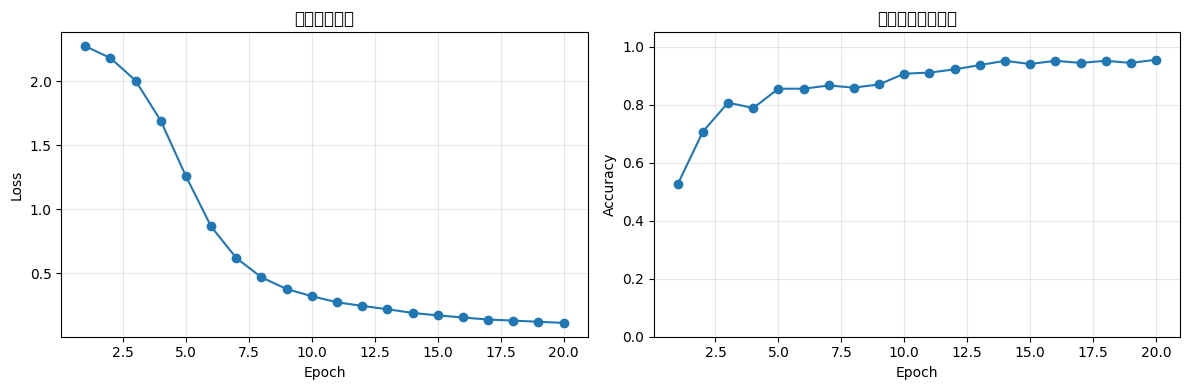

最后一轮训练损失：0.1129
最后一轮验证集准确率：95.56%


In [12]:
epochs_axis = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_axis, train_losses, marker="o")
axes[0].set_title("训练损失曲线")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_axis, val_accuracies, marker="o")
axes[1].set_title("验证集准确率曲线")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1.05)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"最后一轮训练损失：{train_losses[-1]:.4f}")
print(f"最后一轮验证集准确率：{val_accuracies[-1]:.2%}")

## 8. 在测试集上评价模型

验证集主要帮助我们观察训练过程。现在使用此前没有参与训练和模型选择的测试集，对模型进行一次最终评价。

**准确率（Accuracy）** 是预测正确的样本数占全部样本数的比例。只看准确率有时不够，因此我们还会查看混淆矩阵，观察哪些数字容易被误判。

In [13]:
model.eval()
all_true = []
all_pred = []

with torch.no_grad():
    for batch_x, batch_y in test_loader:
        batch_x = batch_x.to(device)
        logits = model(batch_x)
        predictions = logits.argmax(dim=1).cpu().numpy()

        all_pred.extend(predictions.tolist())
        all_true.extend(batch_y.numpy().tolist())

test_acc = accuracy_score(all_true, all_pred)
print(f"测试集准确率：{test_acc:.2%}")
print("\n各类别的分类表现：")
print(classification_report(all_true, all_pred, labels=list(range(10)), zero_division=0))

测试集准确率：97.04%

各类别的分类表现：
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        27
           1       0.93      0.93      0.93        27
           2       1.00      1.00      1.00        27
           3       1.00      1.00      1.00        28
           4       1.00      0.93      0.96        27
           5       0.96      1.00      0.98        27
           6       0.96      1.00      0.98        27
           7       0.96      1.00      0.98        27
           8       0.96      0.88      0.92        26
           9       0.93      0.96      0.95        27

    accuracy                           0.97       270
   macro avg       0.97      0.97      0.97       270
weighted avg       0.97      0.97      0.97       270



### 8.1 阅读混淆矩阵

混淆矩阵的行表示真实类别，列表示模型预测类别。对角线上的数字表示预测正确的数量；非对角线位置则表示发生混淆的情况。

/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 25163 (\N{CJK UNIFIED IDEOGRAPH-624B}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 20889 (\N{CJK UNIFIED IDEOGRAPH-5199}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 23383 (\N{CJK UNIFIED IDEOGRAPH-5B57}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from font(s) DejaVu Sans.
  fig.c

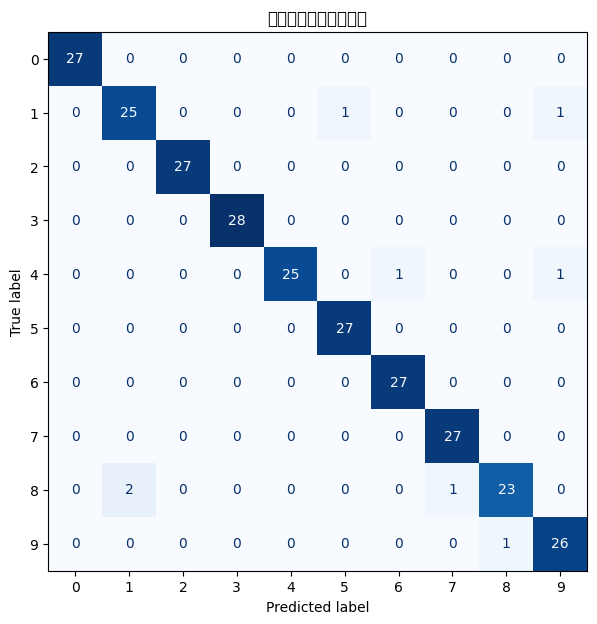

In [14]:
cm = confusion_matrix(all_true, all_pred, labels=list(range(10)))
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=list(range(10)))
fig, ax = plt.subplots(figsize=(8, 7))
display.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
plt.title("手写数字分类混淆矩阵")
plt.show()

## 9. 查看预测结果，并尝试识别单张图片

先从测试集中抽取一些图片，比较真实标签和模型预测结果。然后选择其中一张，观察模型对 10 个类别分别给出了多大的预测概率。

/tmp/ipykernel_694/1174117043.py:17: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_694/1174117043.py:17: UserWarning: Glyph 23454 (\N{CJK UNIFIED IDEOGRAPH-5B9E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_694/1174117043.py:17: UserWarning: Glyph 65306 (\N{FULLWIDTH COLON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_694/1174117043.py:17: UserWarning: Glyph 39044 (\N{CJK UNIFIED IDEOGRAPH-9884}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_694/1174117043.py:17: UserWarning: Glyph 27979 (\N{CJK UNIFIED IDEOGRAPH-6D4B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_694/1174117043.py:17: UserWarning: Glyph 27491 (\N{CJK UNIFIED IDEOGRAPH-6B63}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_694/1174117043.py:17: UserWarning: Glyph 30830 (\N{CJK UNIFIED IDEOGRAPH-786E}) missing from fon

/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 23454 (\N{CJK UNIFIED IDEOGRAPH-5B9E}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 65306 (\N{FULLWIDTH COLON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 39044 (\N{CJK UNIFIED IDEOGRAPH-9884}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 27979 (\N{CJK UNIFIED IDEOGRAPH-6D4B}) missing from font(s) DejaVu Sans.
  fig.canvas.print

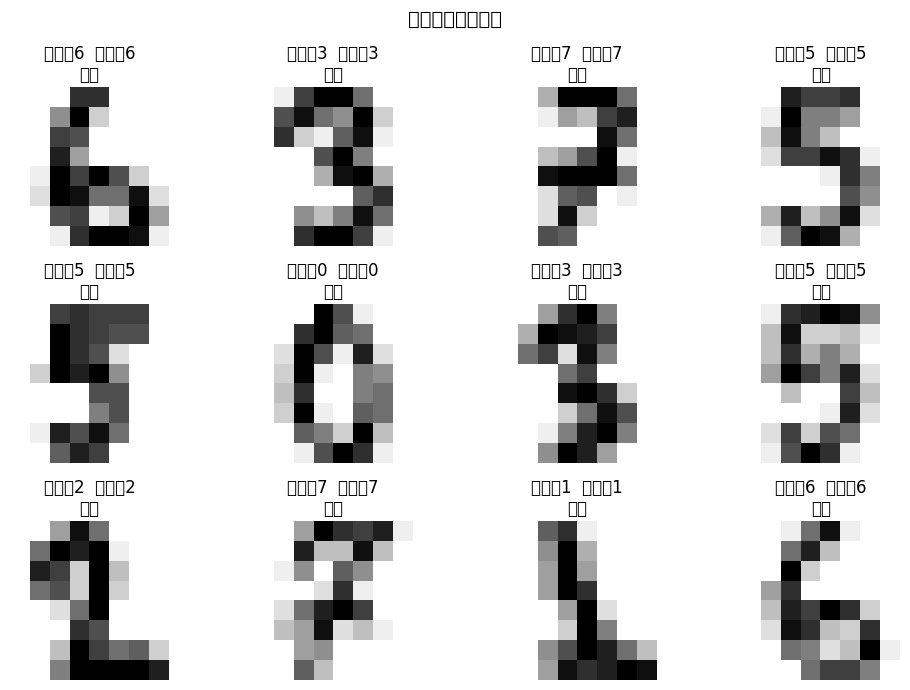

In [15]:
# 显示测试集中的 12 张图片及预测结果
model.eval()
fig, axes = plt.subplots(3, 4, figsize=(10, 7))

for i, ax in enumerate(axes.flat):
    image_tensor, true_label = test_dataset[i]
    with torch.no_grad():
        logits = model(image_tensor.unsqueeze(0).to(device))
        predicted_label = logits.argmax(dim=1).item()

    ax.imshow(image_tensor.squeeze(0).numpy(), cmap="gray_r", vmin=0, vmax=1)
    result_text = "正确" if predicted_label == int(true_label) else "错误"
    ax.set_title(f"真实：{int(true_label)}  预测：{predicted_label}\n{result_text}")
    ax.axis("off")

plt.suptitle("测试图片预测效果", fontsize=14)
plt.tight_layout()
plt.show()

/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 26631 (\N{CJK UNIFIED IDEOGRAPH-6807}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 31614 (\N{CJK UNIFIED IDEOGRAPH-7B7E}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


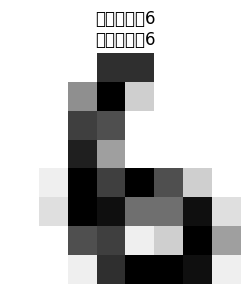

/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 27010 (\N{CJK UNIFIED IDEOGRAPH-6982}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 29575 (\N{CJK UNIFIED IDEOGRAPH-7387}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 27169 (\N{CJK UNIFIED IDEOGRAPH-6A21}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 22411 (\N{CJK UNIFIED IDEOGRAPH-578B}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 23545 (\N{CJK UNIFIED IDEOGRAPH-5BF9}) missing from font(s) DejaVu Sans.
  fig.c

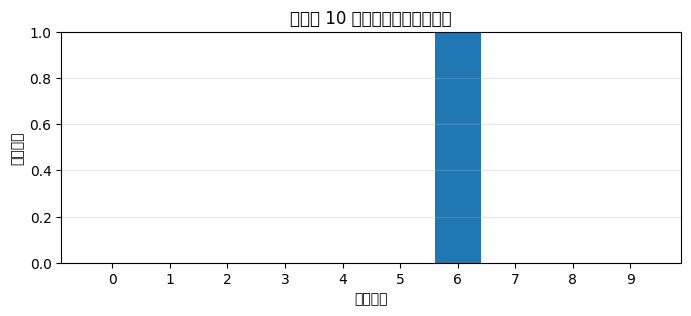

真实标签： 6
预测标签： 6
预测概率最高的类别： 6
各类别概率之和： 1.0


In [16]:
# 对测试集中的一张图片查看各类别概率
index = 0
image_tensor, true_label = test_dataset[index]

model.eval()
with torch.no_grad():
    logits = model(image_tensor.unsqueeze(0).to(device))
    probabilities = torch.softmax(logits, dim=1).squeeze(0).cpu().numpy()
    predicted_label = int(np.argmax(probabilities))

plt.figure(figsize=(3, 3))
plt.imshow(image_tensor.squeeze(0).numpy(), cmap="gray_r", vmin=0, vmax=1)
plt.title(f"真实标签：{int(true_label)}\n预测标签：{predicted_label}")
plt.axis("off")
plt.show()

plt.figure(figsize=(8, 3))
plt.bar(range(10), probabilities)
plt.xticks(range(10))
plt.xlabel("数字类别")
plt.ylabel("预测概率")
plt.title("模型对 10 个数字类别的预测概率")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.show()

print("真实标签：", int(true_label))
print("预测标签：", predicted_label)
print("预测概率最高的类别：", int(probabilities.argmax()))
print("各类别概率之和：", round(float(probabilities.sum()), 4))

## 10. 课堂练习：让模型发生变化

请先保存当前结果，再逐项修改代码，每次只改变一个因素，比较测试集准确率和训练曲线。

### 练习一：改变训练轮数

将 `EPOCHS = 20` 分别改为 `5` 和 `30`，观察：

1. 训练损失有什么变化？
2. 验证集准确率一定会随着 Epoch 增加而持续提高吗？为什么？

### 练习二：改变卷积核数量

把第一层卷积的 `out_channels=16` 改为 `out_channels=8`，并把第二层的 `in_channels=16` 改为 `in_channels=8`。观察模型参数数量、训练速度和分类表现。

**注意：** 本网络第二层输出仍然是 32 个通道，因此后面的 `Linear(32 * 2 * 2, 10)` 不需要改变。

### 练习三：解释模型结构

请用自己的话回答：

1. 为什么模型的输入形状是 `[批次大小, 1, 8, 8]`？
2. 池化两次后，图片的空间尺寸为什么从 `8×8` 变成 `2×2`？
3. 最后一层为什么输出 10 个数？
4. 训练集准确率很高，但测试集准确率明显更低，可能是什么原因？

### 提高任务

尝试将模型改为只使用一层卷积，或者增加一层卷积。比较实验结果，并记录：网络结构、Epoch 数、测试集准确率。不要只依据一次实验就下结论，最好使用相同的数据划分和随机种子进行对比。

## 11. 本节小结

完成本节后，你已经搭建并运行了一个完整的 CNN 图像分类流程：

**图像数据 → 归一化 → 数据集划分 → CNN 建模 → 损失函数与优化器 → 模型训练 → 测试集评价 → 单张图片预测**

请记住三个关键点：

1. 卷积层负责从局部区域提取特征，池化层用于缩小特征图，全连接层负责综合特征并输出类别分数；
2. 训练损失反映模型在训练数据上的误差，验证集用于观察训练过程，测试集用于最终评价；
3. 网络更深、通道更多并不保证模型一定更好，还要结合数据量、训练方法和测试结果判断。

---

### 教师课堂提问参考

- **提问 1：** 普通全连接网络为什么不一定适合直接处理较大的图片？
  - 参考方向：像素数量较多时参数量可能很大；全连接结构没有直接利用图像中局部像素之间的空间关系。
- **提问 2：** 卷积核的参数需要由教师手动填写吗？
  - 参考方向：本例中的演示边缘核是手动设定的；CNN 训练时的卷积核参数通常由优化算法根据数据自动学习。
- **提问 3：** 测试集准确率是 95%，是否表示每一类数字都能达到 95%？
  - 参考方向：不是。总体准确率是所有样本合在一起计算的，需要结合分类报告或混淆矩阵观察各类别表现。